# Tópicos de Big Data — Segundo examen parcial
## Examen práctico · Versión B

**Tiempo máximo:** 90 minutos  
**Calificación de este examen práctico:** 100 puntos (escala de 0 a 100)  
**Nombre:**  SANTIAGO MARTÍNEZ JUÁREZ 
**Grupo:** __512_____  **Fecha:** 26/10/26

### Situación de análisis
Se dispone de un conjunto de datos de viajes de taxi de Nueva York. Tu tarea consiste en aplicar **K-Means** para responder la siguiente pregunta:

> **¿Qué tipos de viajes pagados en efectivo se pueden identificar según la cantidad de pasajeros y la distancia recorrida?**

Trabajarás únicamente con los viajes cuyo tipo de pago sea **`Cash`** y utilizarás las variables **`passenger_count`** y **`trip_distance`**.

### Reglas de entrega
- Escribe tu propio código en las celdas vacías que aparecen después de cada instrucción.
- Ejecuta todas las celdas en orden y conserva las tablas y gráficas resultantes.
- Utiliza **Python, Pandas, NumPy, Matplotlib y scikit-learn**.
- No es necesario utilizar técnicas distintas de las estudiadas en clase.
- Guarda el archivo como **`Examen_B_Apellido_Nombre.ipynb`** y entrégalo con sus resultados visibles.
- El número de clústeres **no está predeterminado**: deberás seleccionarlo y justificarlo con evidencia.

**Ubicación obligatoria del dataset:** dentro de la carpeta de tu examen, guarda el archivo `nyc_taxi_examen.csv` en la subcarpeta `data/raw/`. La ruta relativa desde este notebook será **`data/raw/nyc_taxi_examen.csv`** (no es una ruta absoluta del sistema).

**Estructura de carpetas:**
```text
Examen_B/
└── notebooks/
    └── Examen_B_Apellido_Nombre.ipynb
└── data/
    └── raw/
        └── nyc_taxi_examen.csv
```

## 1. Carga y exploración de datos — 7 puntos · 10 minutos

**Escribe el código necesario para:**
1. Importar las bibliotecas que utilizarás.
2. Cargar el archivo CSV **`../data/raw/nyc_taxi_examen.csv`** en un DataFrame llamado `df`. La ruta es relativa a la carpeta donde está este notebook.
3. Mostrar las **primeras cinco filas**, las **dimensiones**, los **nombres de las columnas** y los **tipos de datos**.
4. Mostrar un resumen estadístico de las columnas numéricas.
5. Comprobar qué valores existen en la columna `payment_type`.

**Evidencia:** deja visibles los resultados de exploración.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid", palette="Set2")
pd.set_option("display.max_columns", None)

ruta_csv = Path("../data/raw/nyc_taxi_examen.csv")

df = pd.read_csv(ruta_csv)

df.head(5)



,Unnamed: 0,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration
0,0,1,2026-08-01 00:03:04,2026-08-01 00:07:51,1.0,0.60,1.0,140.0,262.0,Credit card,6.5,3.5,0.5,2.30,0.00,1.0,13.80,2.5,0.0,0.00,4.783333
1,1,1,2026-08-01 00:38:45,2026-08-01 00:44:02,1.0,0.70,1.0,140.0,262.0,Credit card,6.5,3.5,0.5,3.45,0.00,1.0,14.95,2.5,0.0,0.00,5.283333
2,2,1,NaN,2026-08-01 01:01:07,100.0,1.10,1.0,140.0,263.0,Credit card,7.9,3.5,0.5,2.60,0.00,1.0,15.50,2.5,0.0,0.00,6.266667
3,3,1,2026-08-01 00:27:35,2026-08-01 00:54:27,1.0,5.24,1.0,164.0,80.0,Credit card,29.6,1.0,0.5,8.56,7.46,1.0,51.37,2.5,0.0,0.75,26.866667
4,4,2,2026-08-01 00:39:08,2026-08-01 01:00:23,1.0,3.57,1.0,148.0,141.0,Credit card,20.5,NaN,0.5,5.25,0.00,1.0,31.50,2.5,0.0,0.75,21.250000


In [2]:
print("Dimensiones del DataFrame: ", df.shape)

Dimensiones del DataFrame:  (2427612, 21)


In [3]:
print("Nombres de las columnas: ", df.columns.tolist())

Nombres de las columnas:  ['Unnamed: 0', 'VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee', 'cbd_congestion_fee', 'trip_duration']


In [4]:
# Tipos de datos de cada columna
df.dtypes

Unnamed: 0                 int64
VendorID                   int64
tpep_pickup_datetime         str
tpep_dropoff_datetime        str
passenger_count          float64
trip_distance            float64
RatecodeID               float64
PULocationID             float64
DOLocationID             float64
payment_type                 str
fare_amount              float64
extra                    float64
mta_tax                  float64
tip_amount               float64
tolls_amount             float64
improvement_surcharge    float64
total_amount             float64
congestion_surcharge     float64
Airport_fee              float64
cbd_congestion_fee       float64
trip_duration            float64
dtype: object

In [5]:
# 4. Mostrar un resumen estadístico de las columnas numéricas
display(df.describe())

,Unnamed: 0,VendorID,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,trip_duration
count,2.427612e+06,2.427612e+06,2.415489e+06,2.415470e+06,2.415474e+06,2.415487e+06,2.415475e+06,2.415488e+06,2.415487e+06,2.415462e+06,2.415459e+06,2.415465e+06,2.415481e+06,2.415484e+06,2.415457e+06,2.415481e+06,2.415462e+06,2.415475e+06
mean,1.213806e+06,1.888167e+00,1.296144e+00,3.300702e+00,4.229419e+00,1.641392e+02,1.632236e+02,3.852567e+01,1.567837e+00,4.849912e-01,3.665195e+00,5.938668e-01,9.873437e-01,2.937731e+01,2.254823e+00,1.979527e-01,5.625318e-01,1.561446e+01
std,7.007914e+05,8.086844e-01,1.881923e+00,5.167909e+00,1.720220e+01,6.285386e+01,6.925613e+01,5.423764e+02,1.906552e+00,1.018682e-01,4.234050e+00,2.385704e+00,1.560490e-01,2.592570e+01,7.815658e-01,6.259005e-01,3.314852e-01,2.605773e+02
min,0.000000e+00,1.000000e+00,-5.000000e+00,-9.998763e+01,1.000000e+00,1.000000e+00,1.000000e+00,-1.849600e+03,-7.500000e+00,-5.000000e-01,-9.000000e+01,-1.064600e+02,-1.000000e+00,-1.866890e+03,-2.500000e+00,-2.000000e+00,-7.500000e-01,-3.005175e+05
25%,6.069028e+05,2.000000e+00,1.000000e+00,9.900000e-01,1.000000e+00,1.320000e+02,1.130000e+02,9.300000e+00,0.000000e+00,5.000000e-01,1.000000e+00,0.000000e+00,1.000000e+00,1.638000e+01,2.500000e+00,0.000000e+00,7.500000e-01,7.283333e+00
50%,1.213806e+06,2.000000e+00,1.000000e+00,1.700000e+00,1.000000e+00,1.610000e+02,1.620000e+02,1.350000e+01,1.000000e+00,5.000000e-01,2.950000e+00,0.000000e+00,1.000000e+00,2.154000e+01,2.500000e+00,0.000000e+00,7.500000e-01,1.231667e+01
75%,1.820708e+06,2.000000e+00,1.000000e+00,3.360000e+00,1.000000e+00,2.320000e+02,2.340000e+02,2.190000e+01,2.500000e+00,5.000000e-01,4.560000e+00,0.000000e+00,1.000000e+00,3.145000e+01,2.500000e+00,0.000000e+00,7.500000e-01,2.011667e+01
max,2.427611e+06,7.000000e+00,1.000000e+02,1.686490e+03,9.900000e+01,2.650000e+02,2.650000e+02,1.999559e+04,2.325000e+01,1.150000e+01,4.444400e+02,6.167900e+02,1.000000e+00,5.530740e+03,2.750000e+00,2.700000e+01,7.500000e-01,8.373667e+03


In [6]:
# 5. Comprobar qué valores existen en la columna payment_type
print("Valores en payment_type y sus frecuencias:")
print(df['payment_type'].value_counts())

Valores en payment_type y sus frecuencias:
payment_type
Credit card    2051983
Cash            329533
Dispute          23558
No charge        10413
Name: count, dtype: int64


## 2. Revisión y limpieza de datos — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Crear una copia de los datos originales llamada `df_limpio`.
2. Contar los **valores nulos por columna** y los **registros duplicados** antes de la limpieza.
3. Eliminar registros duplicados y filas que contengan valores nulos.
4. Conservar únicamente los registros que cumplan **todas** estas condiciones:
   - `trip_distance > 0`
   - `passenger_count > 0` y `passenger_count < 100`
   - `fare_amount > 0` y `fare_amount < 10000`
   - `trip_duration > 0`
5. Mostrar cuántos registros quedan después de limpiar.

**Importante:** no elimines registros por valores atípicos utilizando percentiles ni otros métodos adicionales. Si el archivo ya fue depurado, verifica igualmente estas condiciones.

**Evidencia:** muestra los conteos y las dimensiones antes y después de limpiar.

In [7]:
# 1. Crear una copia de los datos originales
df_limpio = df.copy()

In [8]:
# 2. Contar valores nulos y duplicados antes de limpiar
print("Valores nulos por columna antes de limpiar:\n", df_limpio.isna().sum())
print("\nRegistros duplicados antes de limpiar:", df_limpio.duplicated().sum())

Valores nulos por columna antes de limpiar:
 Unnamed: 0                   0
VendorID                     0
tpep_pickup_datetime     12126
tpep_dropoff_datetime    12127
passenger_count          12123
trip_distance            12142
RatecodeID               12138
PULocationID             12125
DOLocationID             12137
payment_type             12125
fare_amount              12124
extra                    12125
mta_tax                  12150
tip_amount               12153
tolls_amount             12147
improvement_surcharge    12131
total_amount             12128
congestion_surcharge     12155
Airport_fee              12131
cbd_congestion_fee       12150
trip_duration            12137
dtype: int64

Registros duplicados antes de limpiar: 0


In [9]:
# 3. Eliminar registros duplicados y filas con valores nulos
df_limpio = df_limpio.drop_duplicates().dropna()

In [10]:
# 4. Conservar únicamente los registros que cumplan las condiciones
df_limpio = df_limpio[
    (df_limpio['trip_distance'] > 0) &
    (df_limpio['passenger_count'] > 0) & 
    (df_limpio['passenger_count'] < 100) &
    (df_limpio['fare_amount'] > 0) & 
    (df_limpio['fare_amount'] < 10000) &
    (df_limpio['trip_duration'] > 0)
]


In [11]:

# 5. Mostrar cuántos registros quedan después de limpiar
print(f"\nDimensiones después de limpiar: {df_limpio.shape}")
print(f"Registros restantes: {df_limpio.shape[0]}")


Dimensiones después de limpiar: (2107024, 21)
Registros restantes: 2107024


## 3. Filtrado y selección de variables — 7 puntos · 5 minutos

**Escribe el código necesario para:**
1. Filtrar los registros de `df_limpio` donde `payment_type` sea exactamente **`Cash`**. Guarda el resultado en `df_cash`.
2. Seleccionar únicamente **`passenger_count`** y **`trip_distance`** para el agrupamiento. Guarda esas dos columnas en un DataFrame llamado `X`.
3. Mostrar la cantidad de viajes filtrados y las estadísticas descriptivas de `X`.

**Recuerda:** utiliza **únicamente estas dos variables** para entrenar K-Means.

**Evidencia:** cantidad de registros y tabla descriptiva.

In [12]:
# 1. Filtrar viajes pagados en efectivo
df_cash = df_limpio[df_limpio['payment_type'] == 'Cash'].copy()

In [13]:
# 2. Seleccionar variables para el agrupamiento
X = df_cash[['passenger_count', 'trip_distance']].copy()

In [14]:
# 3. Mostrar la cantidad de viajes filtrados y estadísticas descriptivas
print(f"Cantidad de viajes pagados en efectivo: {df_cash.shape[0]}")
display(X.describe())

Cantidad de viajes pagados en efectivo: 283537


,passenger_count,trip_distance
count,283537.000000,283537.000000
mean,1.343786,3.842333
std,0.758948,6.210980
min,1.000000,0.010000
25%,1.000000,0.920000
50%,1.000000,1.700000
75%,1.000000,4.370000
max,6.000000,1686.490000


## 4. Transformación y estandarización — 14 puntos · 10 minutos

**Escribe el código necesario para:**
1. Aplicar `np.log1p()` a las dos variables de `X`. Guarda el resultado en `X_log`.
2. Crear un objeto `StandardScaler` y ajustar/transformar `X_log`.
3. Guardar los datos estandarizados en `X_escalado`.
4. Mostrar un resumen estadístico de las variables transformadas y estandarizadas para comprobar el resultado.

**Evidencia:** tabla con media, desviación estándar y otros estadísticos de las variables estandarizadas.

> La transformación logarítmica y la estandarización se aplican para el modelo; conserva `df_cash` con las unidades originales para interpretar los grupos al final.

In [15]:
# 1. Aplicar np.log1p a las dos variables
X_log = np.log1p(X)

In [16]:
# 2. Crear scaler y ajustar/transformar
scaler = StandardScaler()
X_escalado_array = scaler.fit_transform(X_log)

In [17]:
# 3. Guardar los datos en un DataFrame para mantener los nombres de las columnas
X_escalado = pd.DataFrame(X_escalado_array, columns=X.columns, index=X.index)

In [18]:
# 4. Mostrar resumen estadístico
display(X_escalado.describe().round(4))

,passenger_count,trip_distance
count,283537.0000,283537.0000
mean,-0.0000,0.0000
std,1.0000,1.0000
min,-0.4859,-1.5924
25%,-0.4859,-0.7508
50%,-0.4859,-0.3042
75%,-0.4859,0.5966
max,4.5204,8.1298


## 5. Evaluación del número de clústeres — 21 puntos · 20 minutos

**Escribe el código necesario para:**
1. Evaluar los valores de **`k = 2, 3, 4, 5 y 6`** mediante un ciclo.
2. Para cada valor de `k`, entrenar `KMeans` con `random_state=42` y `n_init=10`.
3. Calcular y almacenar la **inercia** (`inertia_`).
4. Calcular y almacenar el **coeficiente de silueta** con `silhouette_score`, usando `sample_size=5000` y `random_state=42` para que el cálculo sea manejable.
5. Construir y mostrar una **tabla comparativa** con las columnas `k`, `Inercia` y `Silueta`.
6. Generar **dos gráficas separadas**: una para el método del codo y otra para el coeficiente de silueta. Ambas deben tener título y etiquetas en los ejes.

**Evidencia:** tabla y dos gráficas.

**Nota:** una inercia menor no basta por sí sola para elegir `k`; considera también la silueta y la interpretación de los grupos.

In [19]:
# 1 a 4. Evaluar k de 2 a 6
k_valores = range(2, 7)
inercias = []
siluetas = []

for k in k_valores:
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas = modelo.fit_predict(X_escalado)
    
    inercias.append(modelo.inertia_)
    
    # Se usa sample_size=5000 para optimizar el rendimiento del cálculo
    silueta = silhouette_score(X_escalado, etiquetas, sample_size=5000, random_state=42)
    siluetas.append(silueta)

In [20]:
# 5. Tabla comparativa
df_metricas = pd.DataFrame({
    'k': k_valores,
    'Inercia': inercias,
    'Silueta': siluetas
})
display(df_metricas)

,k,Inercia,Silueta
0,2,326248.007285,0.550175
1,3,161175.263705,0.592143
2,4,115676.032071,0.608636
3,5,87354.812934,0.615501
4,6,61467.324771,0.552885


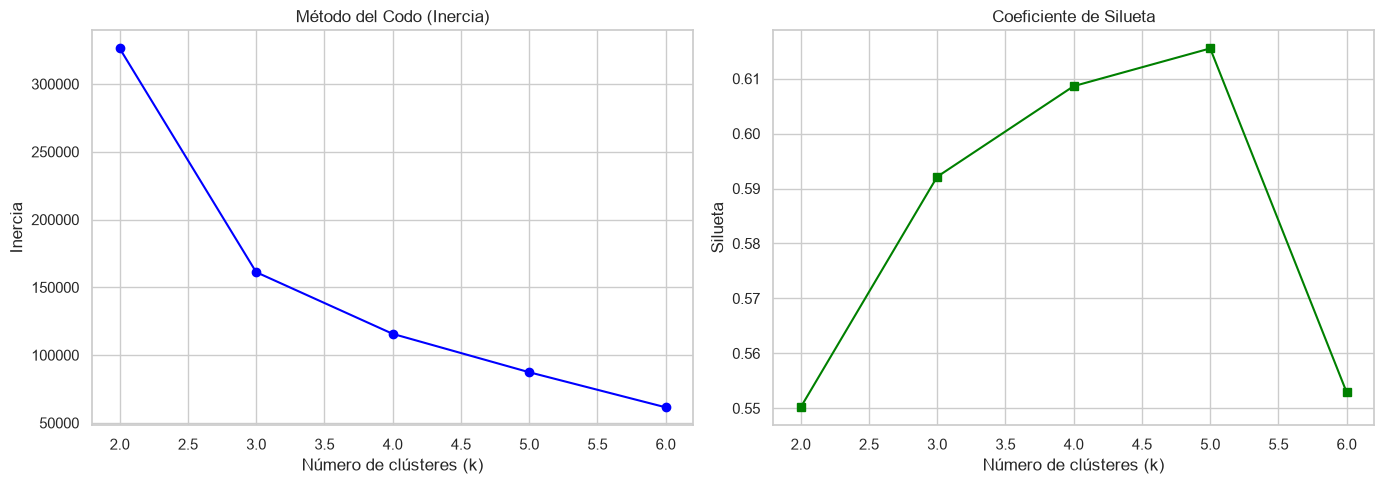

In [21]:
# 6. Generar gráficas separadas
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Gráfica del codo
ax[0].plot(df_metricas['k'], df_metricas['Inercia'], marker='o', color='b')
ax[0].set_title('Método del Codo (Inercia)')
ax[0].set_xlabel('Número de clústeres (k)')
ax[0].set_ylabel('Inercia')

# Gráfica de Silueta
ax[1].plot(df_metricas['k'], df_metricas['Silueta'], marker='s', color='g')
ax[1].set_title('Coeficiente de Silueta')
ax[1].set_xlabel('Número de clústeres (k)')
ax[1].set_ylabel('Silueta')

plt.tight_layout()
plt.show()

## 6. Modelo final y visualización — 14 puntos · 15 minutos

**Escribe el código necesario para:**
1. Elegir un valor de `k` a partir de los resultados anteriores.
2. Entrenar un modelo final `KMeans` con ese valor, `random_state=42` y `n_init=10`.
3. Obtener las etiquetas de clúster para cada viaje.
4. Generar una **gráfica de dispersión** usando las dos columnas de `X_escalado`: eje X = **`passenger_count`**, eje Y = **`trip_distance`**, ambas transformadas y estandarizadas.
5. Colorear los puntos según el clúster asignado.
6. Dibujar los **centroides** del modelo con marcadores **X** de tamaño visible y un color que contraste.
7. Agregar título, nombres de ejes y leyenda de centroides.

**Evidencia:** gráfica final con clústeres y centroides.

**Nota sobre la visualización:** la gráfica debe mostrar los datos y centroides **transformados y estandarizados**, tal como los utiliza K-Means. Los valores de sus ejes no representan directamente las unidades originales.

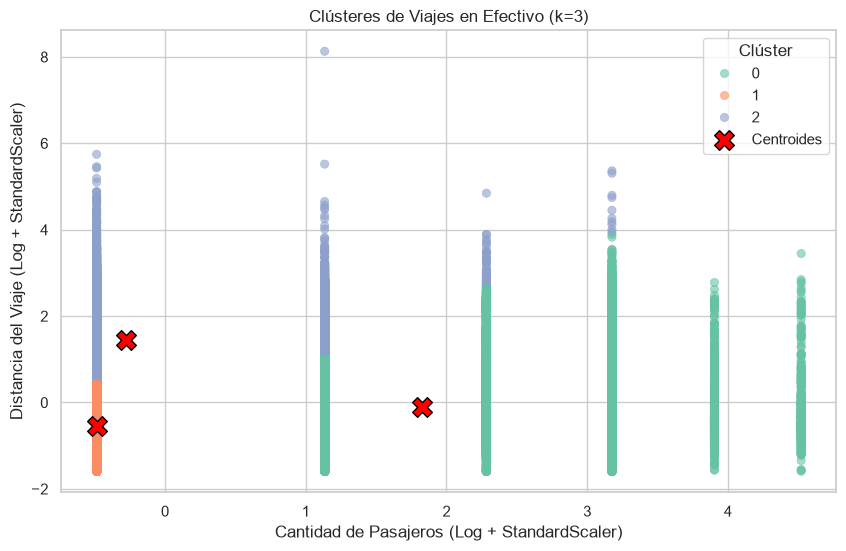

In [22]:
# 1. Elegir valor k
k_optimo = 3

# 2. Entrenar modelo final
modelo_final = KMeans(n_clusters=k_optimo, random_state=42, n_init=10)

# 3. Obtener etiquetas
etiquetas_finales = modelo_final.fit_predict(X_escalado)

# 4 y 5. Gráfica de dispersión
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x=X_escalado['passenger_count'], 
    y=X_escalado['trip_distance'], 
    hue=etiquetas_finales, 
    palette='Set2', 
    alpha=0.6,
    edgecolor=None
)

# 6. Dibujar centroides
centroides = modelo_final.cluster_centers_
plt.scatter(
    centroides[:, 0], 
    centroides[:, 1], 
    marker='X', 
    s=200, 
    c='red', 
    label='Centroides',
    edgecolor='black'
)

# 7. Agregar detalles
plt.title(f'Clústeres de Viajes en Efectivo (k={k_optimo})')
plt.xlabel('Cantidad de Pasajeros (Log + StandardScaler)')
plt.ylabel('Distancia del Viaje (Log + StandardScaler)')
plt.legend(title='Clúster')
plt.show()

## 7. Estadísticos de los clústeres y preguntas de análisis — 23 puntos · 15 minutos

**Parte A. Tabla de estadísticos — 11 puntos**

**Importante:** calcula los estadísticos descriptivos usando los **datos originales de las variables, sin aplicarles la transformación logarítmica ni la estandarización**. Usa las etiquetas del modelo para agrupar los registros, pero toma los valores de `df_cash`, no de `X_escalado`.

**Escribe el código necesario para:**
1. Crear un DataFrame llamado `df_resultado` a partir de `df_cash`.
2. Agregar una columna `cluster` con las etiquetas obtenidas en el modelo final.
3. Agrupar por `cluster` y calcular, para cada grupo:
   - **Cantidad de viajes**.
   - **Media y mediana** de `passenger_count`.
   - **Media y mediana** de `trip_distance`.
4. Mostrar la tabla con valores redondeados a dos decimales. Los resultados deben expresarse en sus **unidades originales**: número de pasajeros y millas para la distancia.

**Evidencia:** tabla de estadísticos por clúster.

In [23]:
# 1. Crear DataFrame a partir de los datos originales
df_resultado = df_cash.copy()

# 2. Agregar la columna de clúster
df_resultado['cluster'] = etiquetas_finales

# 3. Agrupar y calcular estadísticos
tabla_estadisticos = df_resultado.groupby('cluster').agg(
    Cantidad_Viajes=('passenger_count', 'count'),
    Pasajeros_Media=('passenger_count', 'mean'),
    Pasajeros_Mediana=('passenger_count', 'median'),
    Distancia_Media=('trip_distance', 'mean'),
    Distancia_Mediana=('trip_distance', 'median')
).round(2)

# 4. Mostrar la tabla final
display(tabla_estadisticos)

,Cantidad_Viajes,Pasajeros_Media,Pasajeros_Mediana,Distancia_Media,Distancia_Mediana
cluster,,,,,
0,53782,2.66,2.0,3.15,1.60
1,164305,1.00,1.0,1.40,1.20
2,65450,1.13,1.0,10.53,8.87


**Parte B. Preguntas de análisis — 12 puntos (3 puntos por pregunta).** Responde las cuatro preguntas con tus propias palabras. Usa las métricas, la gráfica y la tabla de estadísticos como evidencia. No basta con mencionar el número de clúster.

**Pregunta 1 — Selección de k.** ¿Qué valor de `k` elegiste y por qué? Justifica tu decisión utilizando **inercia, silueta** y, si corresponde, la claridad de los grupos obtenidos.

**Respuesta:**


**Pregunta 2 — Interpretación de grupos.** Describe las características de **cada clúster** a partir de la cantidad de viajes, las medias y las medianas. Asigna a cada grupo un nombre descriptivo.

**Respuesta:**


**Pregunta 3 — Análisis sencillo.** ¿Qué diferencias encuentras entre los grupos con menor y mayor cantidad promedio de pasajeros? Apóyate en la tabla.

**Respuesta:**


**Pregunta 4 — Análisis sencillo.** ¿Los viajes con más pasajeros son siempre los de mayor distancia? Explica qué muestran tus clústeres, sin asumir que todos los viajes se comportan igual.

**Respuesta:**

---
### Lista de verificación antes de entregar

- [ ] Se muestran la carga, exploración, limpieza y filtrado.
- [ ] Se utilizaron las **dos variables indicadas**.
- [ ] Se aplicaron `log1p` y `StandardScaler`.
- [ ] Se calcularon inercia y silueta para `k = 2...6`.
- [ ] Se muestran la tabla de métricas y las dos gráficas de evaluación.
- [ ] Se visualizan los clústeres y sus centroides.
- [ ] Se presenta la tabla de estadísticos calculados sobre los **datos originales**, sin transformación ni estandarización, en sus unidades correspondientes.
- [ ] Se respondieron las cuatro preguntas finales.

**Distribución de puntos (sobre 100):** carga y exploración: 7; limpieza: 14; filtrado y selección: 7; transformación y estandarización: 14; evaluación de k: 21; modelo y visualización: 14; estadísticos: 11; preguntas de análisis: 12. **Total: 100 puntos.**

Pregunta 1 — Selección de k. ¿Qué valor de k elegiste y por qué? Justifica tu decisión utilizando inercia, silueta y, si corresponde, la claridad de los grupos obtenidos.

Respuesta:
Elegí k = 3 (tres grupos) porque es la opción más equilibrada y práctica para entender los datos:

Gráfica del codo (Inercia): Al pasar de 2 a 3 grupos, el "margen de error" cae drásticamente a la mitad (baja de 326,248 a 161,175). Esto nos indica que agrupar la información en 3 ajusta los datos de maravilla.

Puntaje de silueta: Esta calificación nos dice qué tan bien definidos y separados están los grupos. Al usar 3, el puntaje sube a 0.592, confirmando que las categorías son sólidas y no se mezclan entre sí.

Resultados más útiles: Aunque tener 4 o 5 grupos mejora los números un poquito más, quedarse con 3 es la jugada más inteligente. Nos da perfiles de viaje muy claros y diferentes, y evita que nos compliquemos creando categorías de relleno que solo confunden.

Pregunta 2 — Interpretación de grupos. Describe las características de cada clúster a partir de la cantidad de viajes, las medias y las medianas. Asigna a cada grupo un nombre descriptivo.

Respuesta:

Clúster 0: Viajes grupales de distancia media. Es el grupo con menos viajes (53,782). Se trata de viajes compartidos normalmente por 2 o 3 personas (media de 2.66) para recorrer distancias moderadas que rondan entre 1.6 y 3 millas.

Clúster 1: Viajes individuales cortos (el viaje típico). Es el grupo más grande por diferencia (164,305 viajes). Representa el viaje más común en la ciudad: una sola persona moviéndose en trayectos muy cortos de poco más de 1 milla.

Clúster 2: Viajes individuales de larga distancia. Es un grupo de tamaño intermedio (65,450 viajes). Al igual que el Clúster 1, casi siempre llevan a un solo pasajero (media de 1.13), pero se destacan por ser trayectos mucho más largos, recorriendo en promedio entre 8 y 10 millas.

Pregunta 3 — Análisis sencillo ¿Qué diferencias encuentras entre los grupos con menor y mayor cantidad promedio de pasajeros? Apóyate en la tabla.

Respuesta:

El grupo con menor promedio de pasajeros es el Clúster 1 (1.00 pasajero) y el de mayor promedio es el Clúster 0 (2.66 pasajeros). Las diferencias principales son:

Volumen de viajes: El Clúster 1 triplica en cantidad de viajes al Clúster 0 (164,305 frente a 53,782), lo que demuestra que los viajes en efectivo suelen ser predominantemente individuales
Distancia promedio:El Clúster 0 realiza recorridos más largos en promedio que el Clúster 1 (3.15 millas frente a 1.40 millas)
Dispersión de la distancia:El Clúster 0 presenta mayor brecha entre su media (3.15 mi) y su mediana (1.60 mi), a diferencia del Clúster 1, cuyos valores de distancia son más compactos (1.40 mi media vs. 1.00 mi mediana)

Pregunta 4 — Análisis sencillo. ¿Los viajes con más pasajeros son siempre los de mayor distancia? Explica qué muestran tus clústeres, sin asumir que todos los viajes se comportan igual.

Respuesta:

No, una mayor cantidad de pasajeros no implica recorrer trayectos más largos. Los datos del modelo demuestran lo contrario:

Mayor distancia en viajes individuales:** El Clúster 2 registra las distancias más largas (media de 10.53 mi y mediana de 8.87 mi), pero está compuesto casi exclusivamente por viajes de una sola persona (media de 1.13 pasajeros).
Menor distancia en viajes grupales: El Clúster 0, que concentra el mayor promedio de pasajeros (2.66 personas), realiza recorridos considerablemente más cortos (media de 3.15 mi y mediana de 1.60 mi)